# T3 — Análise e visualização do SIASUS em Ijuí

Este notebook reúne as análises do trabalho, da preparação dos dados aos indicadores e gráficos. Execute as células de cima para baixo. A conexão com o MySQL e a leitura da view ocorrem uma vez; as demais etapas usam o mesmo DataFrame.

**Fonte e recorte:** produção ambulatorial do SIASUS/DATASUS, mês de movimento julho de 2026, filtrada para estabelecimentos localizados em Ijuí (`pa_ufmun = '431020'`). O uso de um único mês foi combinado com o professor por causa do volume dos dados.

**Preparação do MySQL:** use MySQL 8. Execute `scripts_gerais/script_completo_dbsia.sql`, carregue o CSV PARS em `dbsia.pars`, execute `scripts_gerais/04-gera-dimtempo-mysql.sql` para criar a dimensão temporal e, por fim, execute a versão atual de `scripts_gerais/view.sql`. A view precisa incluir `PA_PROC_ID` e `PA_TPUPS`. O PARS não está versionado neste repositório.

O notebook salva os CSVs em `analises_geradas/csv/` e os gráficos PNG em `analises_geradas/img/`. Os arquivos de execuções anteriores ficam nessas pastas até serem substituídos.


## 1. Instalar e importar dependências

Instale os pacotes no ambiente Python usado pelo Jupyter. No VS Code, selecione esse mesmo ambiente como kernel.


In [23]:
%pip install pandas mysql-connector-python matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [24]:
from getpass import getpass
from pathlib import Path

import mysql.connector
from mysql.connector import Error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 30)
sns.set_theme(style="whitegrid")

# A pasta fica na raiz do projeto se o notebook for aberto a partir dela.
RAIZ_PROJETO = Path.cwd()
if not (RAIZ_PROJETO / "scripts_gerais").exists():
    RAIZ_PROJETO = Path.cwd().parent
PASTA_CSV = RAIZ_PROJETO / "analises_geradas" / "csv"
PASTA_IMAGENS = RAIZ_PROJETO / "analises_geradas" / "img"
PASTA_CSV.mkdir(parents=True, exist_ok=True)
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)
print(f"CSV: {PASTA_CSV}")
print(f"Gráficos: {PASTA_IMAGENS}")

def salvar_csv(dataframe, nome, index=False, index_label=None):
    caminho = PASTA_CSV / nome
    dataframe.to_csv(caminho, index=index, index_label=index_label, encoding="utf-8-sig")
    print(f"CSV salvo: {caminho}")
    return caminho


CSV: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv
Gráficos: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/img


## 2. Conectar ao MySQL e carregar a view

Informe usuário e senha do MySQL local quando solicitado. A consulta usa um cursor bufferizado e consome o resultado antes de fechar a conexão. A leitura pode demorar e exige memória, pois a view pode conter muitos registros.


In [25]:
usuario_mysql = input("Usuário MySQL: ")
senha_mysql = getpass("Senha MySQL: ")

try:
    conexao = mysql.connector.connect(
        host="localhost",
        user=usuario_mysql,
        password=senha_mysql,
    )
    print("Conexão MySQL estabelecida.")
    with conexao.cursor(buffered=True) as cursor:
        cursor.execute("SELECT * FROM dbsia.pa_ijui")
        colunas = cursor.column_names
        registros = cursor.fetchall()
    conexao.close()
except Error:
    if "conexao" in locals() and conexao.is_connected():
        conexao.close()
    raise

tabela_original = pd.DataFrame(registros, columns=colunas)
print(f"Linhas carregadas: {len(tabela_original):,}")
print(f"Colunas carregadas: {len(tabela_original.columns)}")
display(tabela_original.head())


Conexão MySQL estabelecida.
Linhas carregadas: 65,521
Colunas carregadas: 20


,Ano,Mes,AnoBimestre,AnoTrimestre,Estabelecimento,PA_PROC_ID,Procedimento,Ocupacao,PA_TPUPS,pa_sexo,pa_idade,pa_flidade,pa_cidpri,Diagnostico,MunicipioEstabelecimento,MunicipioPaciente,pa_qtdpro,pa_qtdapr,pa_valpro,pa_valapr
0,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,0301010048,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,70,0,041,1,0000,CID NAO INFORMADO,IJUI,INVALIDO,1,1,6.30,6.30
1,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,0301010048,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,70,0,065,1,0000,CID NAO INFORMADO,IJUI,INVALIDO,3,3,18.90,18.90
2,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,0301010048,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,70,0,059,1,0000,CID NAO INFORMADO,IJUI,INVALIDO,3,3,18.90,18.90
3,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,0301010048,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Psicologo clinico,70,0,068,1,0000,CID NAO INFORMADO,IJUI,INVALIDO,3,3,18.90,18.90
4,2026,7,2026B4,2026T3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,0301010048,CONSULTA DE PROFISSIONAIS DE NIVEL SUPERIOR NA...,Assistente social,70,0,035,1,0000,CID NAO INFORMADO,IJUI,INVALIDO,3,3,18.90,18.90


## 3. Conferir estrutura e requisitos da view

`shape` mostra o número de linhas e colunas; `dtypes` apresenta os tipos retornados pelo conector. A célula verifica os campos necessários. Se algum estiver ausente, recrie a view com `scripts_gerais/view.sql` antes de continuar.


In [26]:
print("Dimensão (linhas, colunas):", tabela_original.shape)
print("\nTipos de variáveis:")
display(tabela_original.dtypes.to_frame("Tipo"))

colunas_necessarias = {
    "Ano", "Mes", "Estabelecimento", "PA_PROC_ID", "PA_TPUPS",
    "Procedimento", "Ocupacao", "pa_sexo", "pa_idade", "pa_flidade",
    "pa_cidpri", "Diagnostico", "MunicipioPaciente",
    "pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr",
}
colunas_faltantes = sorted(colunas_necessarias - set(tabela_original.columns))
if colunas_faltantes:
    raise ValueError(
        "A view está desatualizada ou incompleta. Reexecute scripts_gerais/view.sql. "
        f"Colunas faltantes: {colunas_faltantes}"
    )
print("A view contém as colunas necessárias.")


Dimensão (linhas, colunas): (65521, 20)

Tipos de variáveis:


,Tipo
Ano,int64
Mes,int64
AnoBimestre,str
AnoTrimestre,str
Estabelecimento,str
PA_PROC_ID,str
Procedimento,str
Ocupacao,str
PA_TPUPS,str
pa_sexo,str


A view contém as colunas necessárias.


## 4. Preparar uma cópia para análise

A cópia de análise converte quantidades, valores e idade em números e cria a data de movimento. Valores inválidos são tratados como ausentes nas análises numéricas e as linhas são preservadas.

Linhas idênticas são mantidas porque a view não tem uma chave que confirme se são duplicações indevidas do PARS. Códigos de sexo diferentes de `M`/`F` também são mantidos e contabilizados.

No leiaute SIASUS, `pa_idade` é a idade em anos enquanto `pa_flidade` indica compatibilidade da idade com a faixa prevista para o procedimento.


In [27]:
tabela = tabela_original.copy()
colunas_numericas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr", "pa_idade"]
for coluna in colunas_numericas:
    tabela[coluna] = pd.to_numeric(tabela[coluna], errors="coerce")

for coluna in ["PA_PROC_ID", "PA_TPUPS", "pa_sexo", "pa_cidpri"]:
    tabela[coluna] = tabela[coluna].astype("string").str.strip()

tabela["DataMovimento"] = pd.to_datetime(
    {
        "year": pd.to_numeric(tabela["Ano"], errors="coerce"),
        "month": pd.to_numeric(tabela["Mes"], errors="coerce"),
        "day": 1,
    },
    errors="coerce",
)
tabela["AnoMes"] = tabela["DataMovimento"].dt.to_period("M").astype("string")

tabela["IdadeValida"] = tabela["pa_idade"].between(0, 120)
bins_idade = [0, 5, 10, 15, 20, 30, 40, 50, 60, 70, 80, 121]
rotulos_idade = ["0-4", "5-9", "10-14", "15-19", "20-29", "30-39",
                 "40-49", "50-59", "60-69", "70-79", "80+"]
tabela["FaixaEtaria"] = pd.cut(
    tabela["pa_idade"].where(tabela["IdadeValida"]),
    bins=bins_idade, labels=rotulos_idade, right=False,
)

print("Linhas preservadas na preparação:", len(tabela))
print("Linhas idênticas na view (não removidas):", int(tabela.duplicated().sum()))


Linhas preservadas na preparação: 65521
Linhas idênticas na view (não removidas): 25837


## 5. Qualidade dos dados e exploração inicial

O resumo mostra ausências por coluna e códigos demográficos ou CID fora dos valores usuais. As contagens correspondem a registros, não a pacientes únicos.


In [28]:
ausentes = tabela.isna().sum().sort_values(ascending=False).rename("ValoresAusentes")
display(ausentes.to_frame())
salvar_csv(ausentes.to_frame(), "valores_ausentes.csv", index=True, index_label="Coluna")

print("\nFrequência dos códigos de sexo:")
frequencia_sexo = tabela["pa_sexo"].value_counts(dropna=False).rename_axis("CodigoSexo").to_frame("Registros")
display(frequencia_sexo)
salvar_csv(frequencia_sexo, "frequencia_sexo.csv", index=True, index_label="CodigoSexo")

print("\nIdades ausentes ou fora do intervalo 0-120:", int((~tabela["IdadeValida"]).sum()))
print("Códigos de compatibilidade PA_FLIDADE:")
display(tabela["pa_flidade"].value_counts(dropna=False).rename_axis("PA_FLIDADE").to_frame("Registros"))

colunas_descritivas = ["pa_qtdpro", "pa_qtdapr", "pa_valpro", "pa_valapr"]
display(tabela[colunas_descritivas].describe().T)
salvar_csv(tabela[colunas_descritivas].describe().T, "estatisticas_descritivas.csv", index=True, index_label="Variavel")


,ValoresAusentes
FaixaEtaria,876
Diagnostico,9
Mes,0
IdadeValida,0
AnoMes,0
DataMovimento,0
pa_valapr,0
pa_valpro,0
pa_qtdapr,0
pa_qtdpro,0


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/valores_ausentes.csv

Frequência dos códigos de sexo:


,Registros
CodigoSexo,
F,32080
M,30763
0,2678


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/frequencia_sexo.csv

Idades ausentes ou fora do intervalo 0-120: 876
Códigos de compatibilidade PA_FLIDADE:


,Registros
PA_FLIDADE,
1,64343
3,862
0,316


,count,mean,std,min,25%,50%,75%,max
pa_qtdpro,65521.0,7.827414,55.969743,0.0,1.00,1.00,1.00,6284.00
pa_qtdapr,65521.0,5.928450,50.663850,0.0,0.00,1.00,1.00,5337.00
pa_valpro,65521.0,103.260753,656.816191,0.0,1.53,6.30,17.67,60741.37
pa_valapr,65521.0,101.917093,657.965503,0.0,0.00,2.81,11.00,60741.37


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/estatisticas_descritivas.csv


PosixPath('/Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/estatisticas_descritivas.csv')

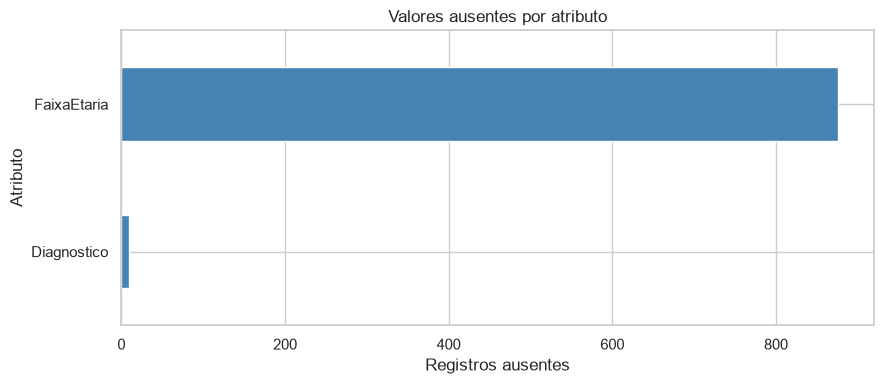

In [29]:
nulos_plot = ausentes[ausentes > 0].sort_values()
if not nulos_plot.empty:
    ax = nulos_plot.plot(kind="barh", figsize=(9, 4), color="steelblue")
    ax.set_title("Valores ausentes por atributo")
    ax.set_xlabel("Registros ausentes")
    ax.set_ylabel("Atributo")
    plt.tight_layout()
    plt.savefig(PASTA_IMAGENS / "valores_ausentes.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Nenhum valor ausente encontrado nas colunas da view.")


## 6. Indicadores gerais de produção e recursos financeiros

`pa_qtdpro` e `pa_valpro` são apresentados; `pa_qtdapr` e `pa_valapr` são aprovados. O gasto médio aprovado é calculado como razão entre valor aprovado total e quantidade aprovada total, evitando tirar média simples de médias por linha.


In [30]:
totais = pd.DataFrame([{
    "Registros": len(tabela),
    "QuantidadeApresentada": tabela["pa_qtdpro"].sum(),
    "QuantidadeAprovada": tabela["pa_qtdapr"].sum(),
    "ValorApresentado": tabela["pa_valpro"].sum(),
    "ValorAprovado": tabela["pa_valapr"].sum(),
}])
totais["DiferencaQuantidade"] = totais["QuantidadeApresentada"] - totais["QuantidadeAprovada"]
totais["DiferencaValor"] = totais["ValorApresentado"] - totais["ValorAprovado"]
totais["GastoMedioAprovadoPorUnidade"] = np.where(
    totais["QuantidadeAprovada"] > 0,
    totais["ValorAprovado"] / totais["QuantidadeAprovada"],
    np.nan,
)
display(totais.T.rename(columns={0: "Valor"}))
salvar_csv(totais, "indicadores_gerais.csv")


,Valor
Registros,6.552100e+04
QuantidadeApresentada,5.128600e+05
QuantidadeAprovada,3.884380e+05
ValorApresentado,6.765748e+06
ValorAprovado,6.677710e+06
DiferencaQuantidade,1.244220e+05
DiferencaValor,8.803793e+04
GastoMedioAprovadoPorUnidade,1.719119e+01


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/indicadores_gerais.csv


PosixPath('/Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/indicadores_gerais.csv')

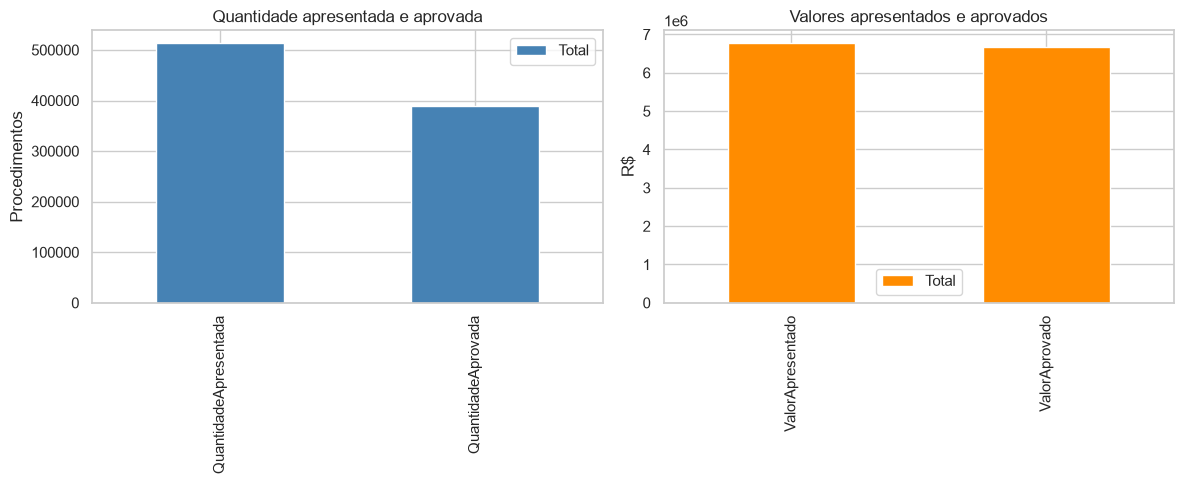

In [31]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
totais[["QuantidadeApresentada", "QuantidadeAprovada"]].T.plot(
    kind="bar", ax=eixos[0], color=["steelblue"]
)
eixos[0].set_title("Quantidade apresentada e aprovada")
eixos[0].set_ylabel("Procedimentos")
eixos[0].legend(["Total"])
totais[["ValorApresentado", "ValorAprovado"]].T.plot(
    kind="bar", ax=eixos[1], color=["darkorange"]
)
eixos[1].set_title("Valores apresentados e aprovados")
eixos[1].set_ylabel("R$")
eixos[1].legend(["Total"])
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "producao_apresentada_aprovada.png", dpi=160, bbox_inches="tight")
plt.show()


## 7. Mês, bimestre e trimestre

A análise usa somente julho de 2026 devido ao volume de dados. O agrupamento mostra os períodos e quantos meses têm dados. Com apenas um mês, não é possível identificar tendências, picos ou quedas.


In [32]:
mensal = (
    tabela.groupby(["Ano", "Mes", "AnoMes"], dropna=False, as_index=False)
    .agg(
        Registros=("AnoMes", "size"),
        QuantidadeApresentada=("pa_qtdpro", "sum"),
        QuantidadeAprovada=("pa_qtdapr", "sum"),
        ValorApresentado=("pa_valpro", "sum"),
        ValorAprovado=("pa_valapr", "sum"),
    )
    .sort_values(["Ano", "Mes"])
)
bimestral = (tabela.groupby("AnoBimestre", dropna=False, as_index=False)
    .agg(MesesComDados=("AnoMes", "nunique"), Registros=("AnoMes", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum")))
trimestral = (tabela.groupby("AnoTrimestre", dropna=False, as_index=False)
    .agg(MesesComDados=("AnoMes", "nunique"), Registros=("AnoMes", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum")))
print("Produção mensal:")
display(mensal)
print("Bimestre:")
display(bimestral)
print("Trimestre:")
display(trimestral)
salvar_csv(mensal, "producao_mensal.csv")
salvar_csv(bimestral, "producao_bimestral.csv")
salvar_csv(trimestral, "producao_trimestral.csv")
if tabela["AnoMes"].nunique() <= 1:
    print("Há somente um mês disponível: evolução temporal e comparação histórica não se aplicam a esta execução.")


Produção mensal:


,Ano,Mes,AnoMes,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,2026,7,2026-07,65521,512860.0,388438.0,6765747.78,6677709.85


Bimestre:


,AnoBimestre,MesesComDados,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,2026B4,1,65521,512860.0,388438.0,6765747.78,6677709.85


Trimestre:


,AnoTrimestre,MesesComDados,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,2026T3,1,65521,512860.0,388438.0,6765747.78,6677709.85


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/producao_mensal.csv
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/producao_bimestral.csv
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/producao_trimestral.csv
Há somente um mês disponível: evolução temporal e comparação histórica não se aplicam a esta execução.


In [33]:
if len(mensal) > 1:
    ax = mensal.plot(x="AnoMes", y=["QuantidadeApresentada", "QuantidadeAprovada"],
                     marker="o", figsize=(10, 4))
    ax.set_title("Produção ambulatorial por mês")
    ax.set_xlabel("Mês de movimento")
    ax.set_ylabel("Procedimentos")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(PASTA_IMAGENS / "producao_mensal.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Gráfico de tendência não gerado: a base tem um único mês, conforme o recorte acordado.")


Gráfico de tendência não gerado: a base tem um único mês, conforme o recorte acordado.


## 8. Procedimentos, ocupações e gasto médio por procedimento

O ranking usa quantidade aprovada. A média unitária por procedimento é `valor aprovado / quantidade aprovada` para cada grupo, com `NaN` quando a quantidade aprovada é zero. Essa medida não representa necessariamente o custo por paciente ou por atendimento.


In [34]:
def resumir_grupo(coluna):
    resumo = (
        tabela.groupby(coluna, dropna=False, as_index=False)
        .agg(Registros=(coluna, "size"),
             QuantidadeApresentada=("pa_qtdpro", "sum"),
             QuantidadeAprovada=("pa_qtdapr", "sum"),
             ValorApresentado=("pa_valpro", "sum"),
             ValorAprovado=("pa_valapr", "sum"))
    )
    resumo["GastoMedioAprovadoPorUnidade"] = (
        resumo["ValorAprovado"] / resumo["QuantidadeAprovada"].where(resumo["QuantidadeAprovada"].ne(0))
    )
    resumo["GastoMedioApresentadoPorUnidade"] = (
        resumo["ValorApresentado"] / resumo["QuantidadeApresentada"].where(resumo["QuantidadeApresentada"].ne(0))
    )
    return resumo.sort_values("QuantidadeAprovada", ascending=False)

procedimentos = resumir_grupo("Procedimento")
ocupacoes = resumir_grupo("Ocupacao")
print("20 procedimentos por quantidade aprovada:")
display(procedimentos.head(20))
print("20 ocupações/especialidades por quantidade aprovada:")
display(ocupacoes.head(20))
salvar_csv(procedimentos, "producao_por_procedimento.csv")
salvar_csv(ocupacoes, "producao_por_ocupacao.csv")
salvar_csv(procedimentos.head(20), "top20_procedimentos.csv")
salvar_csv(ocupacoes.head(20), "top20_ocupacoes.csv")


20 procedimentos por quantidade aprovada:


,Procedimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado,GastoMedioAprovadoPorUnidade,GastoMedioApresentadoPorUnidade
339,FORMOTEROL 12 MCG + BUDESONIDA 400 MCG ÿ(POR C...,1654,102546.0,26590.0,0.00,0.00,0.000000,0.000000
347,GABAPENTINA 300 MG (POR CAPSULA),366,28410.0,15000.0,0.00,0.00,0.000000,0.000000
399,LEFLUNOMIDA 20 MG (POR COMPRIMIDO),454,13615.0,13615.0,0.00,0.00,0.000000,0.000000
83,AZATIOPRINA 50 MG (POR COMPRIMIDO),156,11770.0,11770.0,0.00,0.00,0.000000,0.000000
340,FORMOTEROL 6MCG + BUDESONIDA 200 MCG (POR CAPS...,153,10040.0,10040.0,0.00,0.00,0.000000,0.000000
421,"METOTREXATO 2,5 MG (POR COMPRIMIDO)",282,9696.0,9696.0,0.00,0.00,0.000000,0.000000
168,CONSULTA MEDICA EM ATENCAO ESPECIALIZADA,7359,10822.0,9515.0,108040.00,94970.00,9.981083,9.983367
721,SULFASSALAZINA 500 MG (POR COMPRIMIDO),86,8640.0,8640.0,0.00,0.00,0.000000,0.000000
154,CLOZAPINA 100 MG (POR COMPRIMIDO),85,8333.0,8333.0,0.00,0.00,0.000000,0.000000
74,ATORVASTATINA 40 MG (POR COMPRIMIDO),203,7656.0,7656.0,0.00,0.00,0.000000,0.000000


20 ocupações/especialidades por quantidade aprovada:


,Ocupacao,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado,GastoMedioAprovadoPorUnidade,GastoMedioApresentadoPorUnidade
9,Farmaceutico,7703,338018.0,241890.0,1611852.72,1605569.36,6.637601,4.768541
3,Biomedico,370,31839.0,31747.0,158602.14,158332.06,4.987308,4.981379
10,Farmaceutico analista clinico,2097,36090.0,30581.0,184163.24,147964.00,4.838429,5.102888
7,Enfermeiro,8505,22405.0,19213.0,79737.70,62291.11,3.242133,3.558924
43,Medico oftalmologista,15251,15501.0,7448.0,348038.14,434832.52,58.382454,22.452625
26,Medico clinico,1678,7686.0,6665.0,80009.56,71589.17,10.741061,10.409779
60,Tecnico de enfermagem,606,9093.0,5785.0,4939.67,2941.31,0.508437,0.543239
33,Medico em radiologia e diagnostico por imagem,2849,5486.0,4849.0,319523.86,264943.67,54.638827,58.243503
58,Psicologo clinico,3982,4829.0,4205.0,29644.38,29291.58,6.965893,6.138824
12,Fonoaudiologo geral,2686,3477.0,3477.0,691567.06,691567.06,198.897630,198.897630


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/producao_por_procedimento.csv
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/producao_por_ocupacao.csv
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/top20_procedimentos.csv
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/top20_ocupacoes.csv


PosixPath('/Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/top20_ocupacoes.csv')

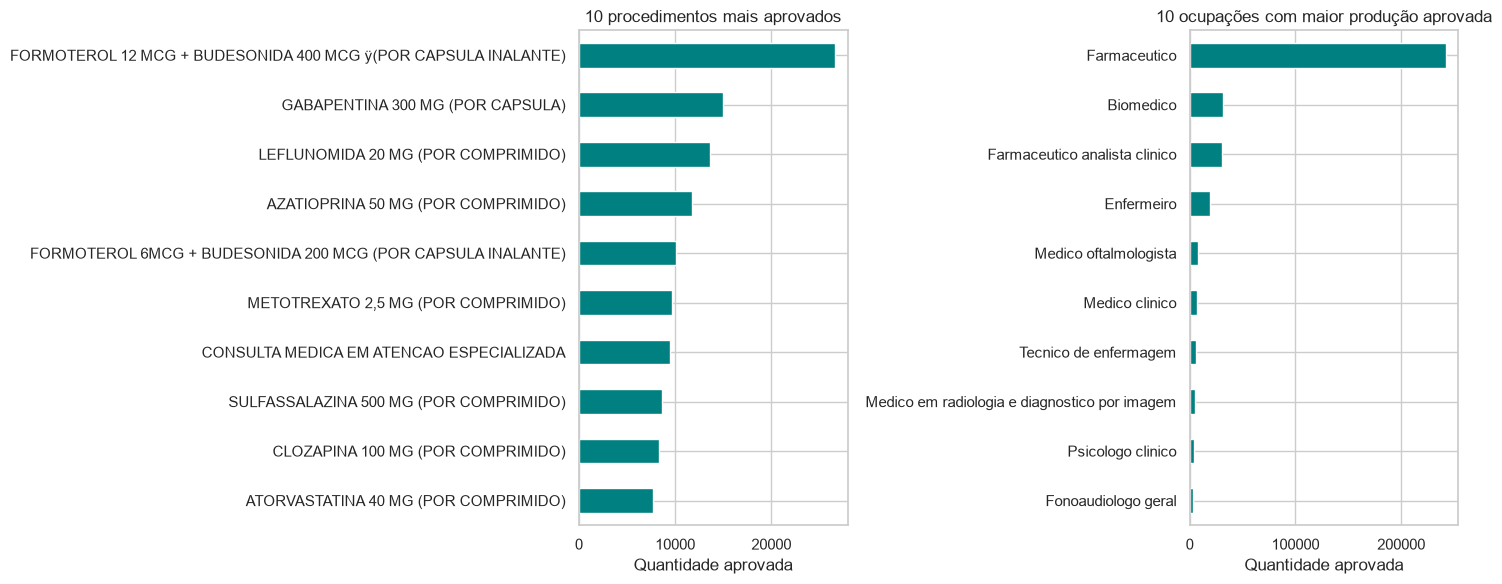

In [35]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 6))
for eixo, dados_grafico, coluna_rotulo, titulo in [
    (eixos[0], procedimentos.head(10).sort_values("QuantidadeAprovada"), "Procedimento", "10 procedimentos mais aprovados"),
    (eixos[1], ocupacoes.head(10).sort_values("QuantidadeAprovada"), "Ocupacao", "10 ocupações com maior produção aprovada"),
]:
    dados_grafico.plot(x=coluna_rotulo, y="QuantidadeAprovada", kind="barh", ax=eixo, legend=False, color="teal")
    eixo.set_title(titulo)
    eixo.set_xlabel("Quantidade aprovada")
    eixo.set_ylabel("")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "top_procedimentos_ocupacoes.png", dpi=160, bbox_inches="tight")
plt.show()


### Como interpretar o gasto médio

Compare a coluna `GastoMedioAprovadoPorUnidade` entre procedimentos apenas com cautela: cada procedimento pode ter unidade de quantidade diferente. Não apresentamos a evolução temporal do gasto médio por conta de estarmos usando somente um mês.


## 9. Produção por estabelecimento

A junção com o cadastro CNES do RS foi conferida no banco: os 65.521 registros da view têm estabelecimento preenchido. A tabela e o gráfico abaixo mostram a produção agrupada por estabelecimento.


,Estabelecimento,Registros,QuantidadeApresentada,QuantidadeAprovada,ValorApresentado,ValorAprovado
0,17 COORDENADORIA REGIONAL DE SAUDE,7573,337855.0,241727.0,1611247.92,1604964.56
12,LABORATORIO DE ANALISES CLINICAS UNILAB,300,29720.0,29720.0,147391.43,147391.43
11,HOSPITAL DE CLINICAS IJUI,19493,33566.0,27838.0,3378200.00,3281936.03
8,CISA,1766,30553.0,24659.0,217267.85,167357.92
17,UNIDADE DE PRONTO ATENDIMENTO DR MARTIN CESAR ...,203,24882.0,21533.0,68317.20,65916.54
10,HOSPITAL BOM PASTOR IJUI,19162,19166.0,10173.0,353881.87,431744.32
9,HEMOVITA,159,8117.0,8117.0,42124.13,42124.13
4,CENTRO DE ATENCAO PSICOSSOCIAL CAPS DO BOSQUE,4323,7997.0,5176.0,4592.70,4592.70
5,CENTRO DE ATENCAO PSICOSSOCIAL CAPS INFANTIL C...,2825,4215.0,3447.0,4002.10,4002.10
3,CENTRO DE ATENCAO PSICOSSOCIAL CAPS COLMEIA,1048,3494.0,3324.0,9161.82,9161.82


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/producao_por_estabelecimento.csv


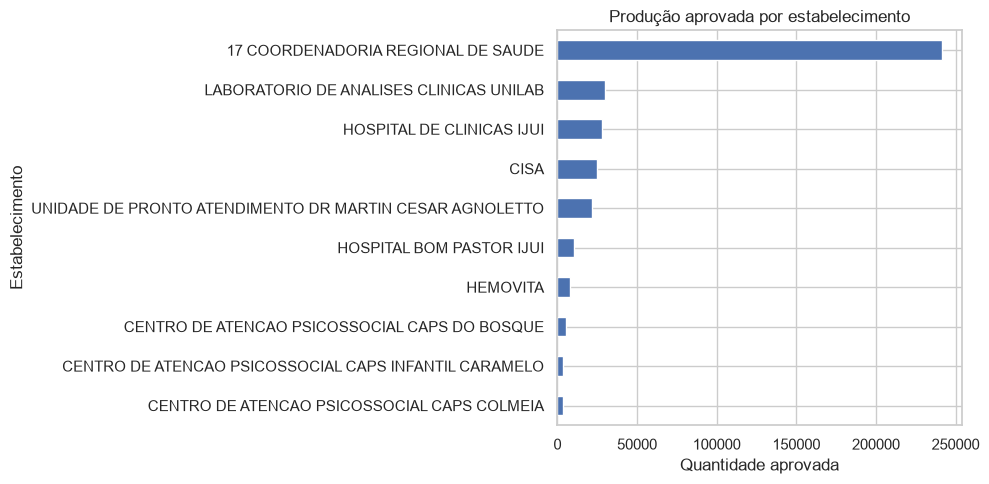

In [36]:
estabelecimentos = (
    tabela.groupby("Estabelecimento", dropna=False, as_index=False)
    .agg(Registros=("Procedimento", "size"),
         QuantidadeApresentada=("pa_qtdpro", "sum"),
         QuantidadeAprovada=("pa_qtdapr", "sum"),
         ValorApresentado=("pa_valpro", "sum"),
         ValorAprovado=("pa_valapr", "sum"))
    .sort_values("QuantidadeAprovada", ascending=False)
)
display(estabelecimentos.head(20))
salvar_csv(estabelecimentos, "producao_por_estabelecimento.csv")
estabelecimentos_identificados = estabelecimentos[estabelecimentos["Estabelecimento"].notna()]
if estabelecimentos_identificados.empty:
    print("ATENÇÃO: não há nomes de estabelecimentos na view; ranking não disponível até corrigir a junção CNES.")
else:
    graf_est = estabelecimentos_identificados.nlargest(10, "QuantidadeAprovada").sort_values("QuantidadeAprovada")
    ax = graf_est.plot(x="Estabelecimento", y="QuantidadeAprovada", kind="barh", legend=False, figsize=(10, 5))
    ax.set_title("Produção aprovada por estabelecimento")
    ax.set_xlabel("Quantidade aprovada")
    plt.tight_layout()
    plt.savefig(PASTA_IMAGENS / "producao_por_estabelecimento.png", dpi=160, bbox_inches="tight")
    plt.show()


## 10. Perfil demográfico por sexo e faixa etária

As categorias de sexo encontradas são preservadas, inclusive o código `0`. As faixas etárias incluem idades entre 0 e 120 anos. Registros com idade ausente ou fora dessa faixa permanecem na base, mas não entram no cruzamento etário.


In [37]:
perfil_sexo = tabela["pa_sexo"].value_counts(dropna=False).rename_axis("PA_SEXO").to_frame("Registros")
perfil_etario_sexo = pd.crosstab(tabela["FaixaEtaria"], tabela["pa_sexo"], dropna=True)
print("Distribuição por sexo:")
display(perfil_sexo)
print("Registros por faixa etária e código de sexo:")
display(perfil_etario_sexo)
salvar_csv(perfil_sexo, "perfil_por_sexo.csv", index=True, index_label="PA_SEXO")
salvar_csv(perfil_etario_sexo, "resumo_perfil_demografico.csv", index=True, index_label="FAIXA_ETARIA")


Distribuição por sexo:


,Registros
PA_SEXO,
F,32080
M,30763
0,2678


Registros por faixa etária e código de sexo:


pa_sexo,0,F,M
FaixaEtaria,,,
0-4,41,797,1612
5-9,88,707,1622
10-14,90,1220,1598
15-19,92,962,1084
20-29,188,1350,1100
30-39,229,2223,1766
40-49,282,3206,3153
50-59,295,4817,4220
60-69,239,7072,5711


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/perfil_por_sexo.csv
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_perfil_demografico.csv


PosixPath('/Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_perfil_demografico.csv')

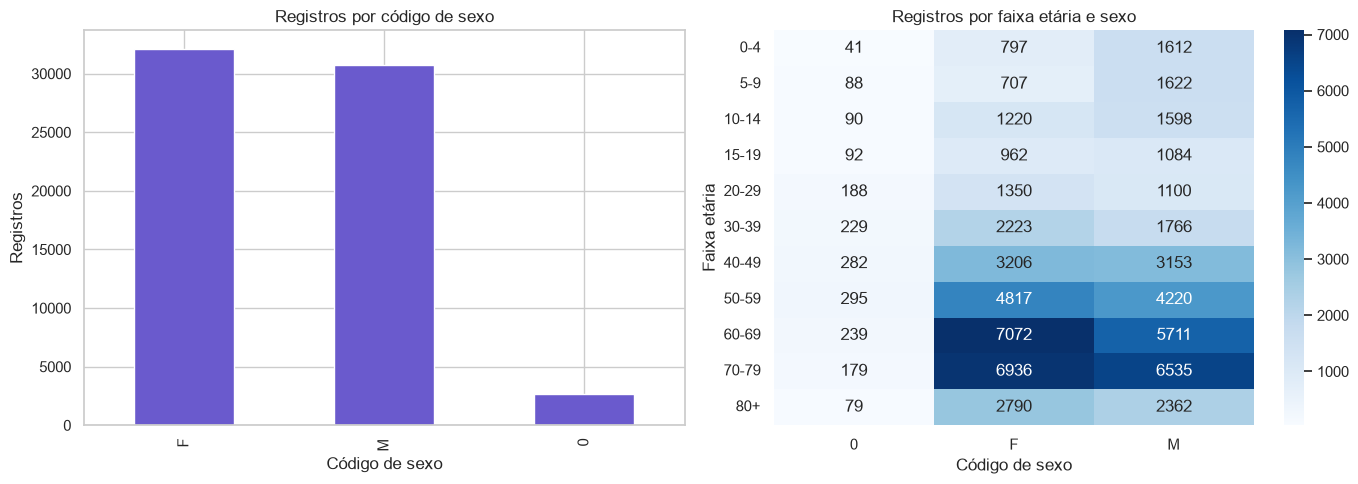

In [38]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
perfil_sexo["Registros"].plot(kind="bar", ax=eixos[0], color="slateblue")
eixos[0].set_title("Registros por código de sexo")
eixos[0].set_xlabel("Código de sexo")
eixos[0].set_ylabel("Registros")

sns.heatmap(perfil_etario_sexo, annot=True, fmt="d", cmap="Blues", ax=eixos[1])
eixos[1].set_title("Registros por faixa etária e sexo")
eixos[1].set_xlabel("Código de sexo")
eixos[1].set_ylabel("Faixa etária")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "perfil_demografico.png", dpi=160, bbox_inches="tight")
plt.show()


## 11. Diagnósticos principais (CID)

A contagem é por registro, não por paciente. São separados códigos e descrições que representam ausência, invalidade ou falta de identificação. Não aparecem como diagnósticos clínicos no ranking.


In [39]:
cid = tabela["pa_cidpri"].astype("string").str.strip()
diagnostico = tabela["Diagnostico"].astype("string").str.strip()
diagnostico_normalizado = diagnostico.str.upper()
rotulos_cid_especial = {"CID NAO INFORMADO", "CID NÃO INFORMADO", "CID NÃO IDENTIFICADO", "CID INVALIDO"}
sem_cid_utilizavel = (
    cid.isna() | cid.isin(["", "0000", "9999"])
    | diagnostico.isna() | diagnostico.eq("")
    | diagnostico_normalizado.isin(rotulos_cid_especial)
)
print(f"Registros sem diagnóstico CID utilizável: {int(sem_cid_utilizavel.sum()):,} de {len(tabela):,}")
top_diagnosticos = (
    diagnostico.loc[~sem_cid_utilizavel & diagnostico.notna()]
    .value_counts().head(10).rename_axis("Diagnostico").to_frame("Registros")
)
display(top_diagnosticos)
salvar_csv(top_diagnosticos, "resumo_top10_diagnosticos.csv", index=True, index_label="Diagnostico")


Registros sem diagnóstico CID utilizável: 44,528 de 65,521


,Registros
Diagnostico,
H90.5 Perda de audicao neuro-sensorial NE,2228
F84.9 Transt globais NE do desenvolv,1323
F84.0 Autismo infantil,1082
I51.6 Doenc cardiovascular NE,864
J45.0 Asma predom alergica,782
R52.0 Dor aguda,642
C50.1 Porcao central da mama,618
F71.0 Mencao ausencia de ou compr minimo comport,571
F70.0 Mencao ausencia de ou compr minimo comport,534


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_top10_diagnosticos.csv


PosixPath('/Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_top10_diagnosticos.csv')

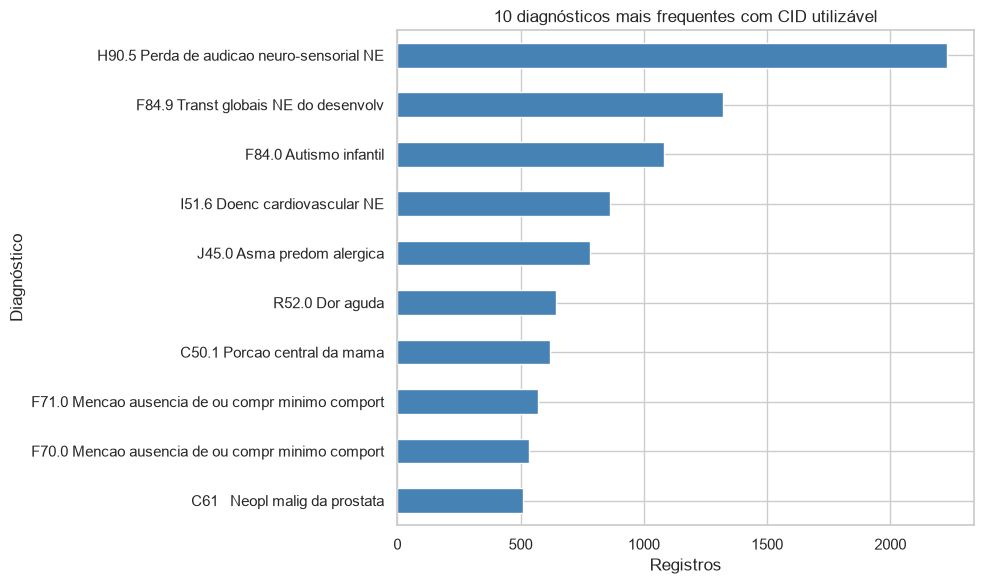

In [40]:
if not top_diagnosticos.empty:
    ax = top_diagnosticos["Registros"].sort_values().plot(kind="barh", figsize=(10, 6), color="steelblue")
    ax.set_title("10 diagnósticos mais frequentes com CID utilizável")
    ax.set_xlabel("Registros")
    ax.set_ylabel("Diagnóstico")
    plt.tight_layout()
    plt.savefig(PASTA_IMAGENS / "top10_diagnosticos.png", dpi=160, bbox_inches="tight")
    plt.show()


## 12. Fluxos regionais e município de origem

A view fornece a descrição do município de origem. `INVALIDO`, `ESTRANGEIRO` e valores ausentes são contabilizados separadamente e não aparecem como municípios na tabela de frequências nem no gráfico. As contagens são de registros de produção, não de pessoas únicas.


In [41]:
municipios = tabela["MunicipioPaciente"].astype("string").str.strip()
municipios_normalizados = municipios.str.upper()
rotulo_invalido = municipios_normalizados.eq("INVALIDO").fillna(False)
rotulo_estrangeiro = municipios_normalizados.eq("ESTRANGEIRO").fillna(False)
municipio_ausente = (
    municipios.isna()
    | municipios.eq("")
    | municipios_normalizados.isin(["NÃO INFORMADO", "NAO INFORMADO"])
).fillna(False)
municipio_ijui = municipios_normalizados.eq("IJUI").fillna(False)
municipio_externo_identificado = ~(
    rotulo_invalido | rotulo_estrangeiro | municipio_ijui | municipio_ausente
).fillna(False)

municipios_validos = municipios.loc[
    ~(rotulo_invalido | rotulo_estrangeiro | municipio_ausente)
]
frequencia_municipios = (
    municipios_validos.value_counts(dropna=False)
    .rename_axis("MunicipioPaciente")
    .to_frame("Registros")
)
display(frequencia_municipios.head(20))
salvar_csv(
    frequencia_municipios.head(20),
    "top20_municipios_origem.csv",
    index=True,
    index_label="MunicipioPaciente",
)

print(f"Registros com descrição INVALIDO: {int(rotulo_invalido.sum()):,}")
print(f"Registros com origem estrangeira: {int(rotulo_estrangeiro.sum()):,}")
print(f"Registros com município informado como Ijuí: {int(municipio_ijui.sum()):,}")
print(f"Registros de outros municípios identificados: {int(municipio_externo_identificado.sum()):,}")
print(f"Registros sem município informado: {int(municipio_ausente.sum()):,}")
print("INVALIDO, ESTRANGEIRO e ausências não são apresentados como municípios.")
print("As contagens são de registros de produção, não de pacientes únicos.")
resumo_origem = pd.DataFrame([{
    "Ijuí": int(municipio_ijui.sum()),
    "OutrosMunicipiosIdentificados": int(municipio_externo_identificado.sum()),
    "MunicipioInvalido": int(rotulo_invalido.sum()),
    "OrigemEstrangeira": int(rotulo_estrangeiro.sum()),
    "SemMunicipioInformado": int(municipio_ausente.sum()),
}])
salvar_csv(resumo_origem, "resumo_fluxos_regionais.csv")


,Registros
MunicipioPaciente,
IJUI,33034
PANAMBI,3073
JOIA,2471
CRISSIUMAL,1848
CATUIPE,1756
SANTO AUGUSTO,1725
AUGUSTO PESTANA,1619
CONDOR,1186
AJURICABA,1051


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/top20_municipios_origem.csv
Registros com descrição INVALIDO: 2,678
Registros com origem estrangeira: 0
Registros com município informado como Ijuí: 33,034
Registros de outros municípios identificados: 29,809
Registros sem município informado: 0
INVALIDO, ESTRANGEIRO e ausências não são apresentados como municípios.
As contagens são de registros de produção, não de pacientes únicos.
CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_fluxos_regionais.csv


PosixPath('/Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_fluxos_regionais.csv')

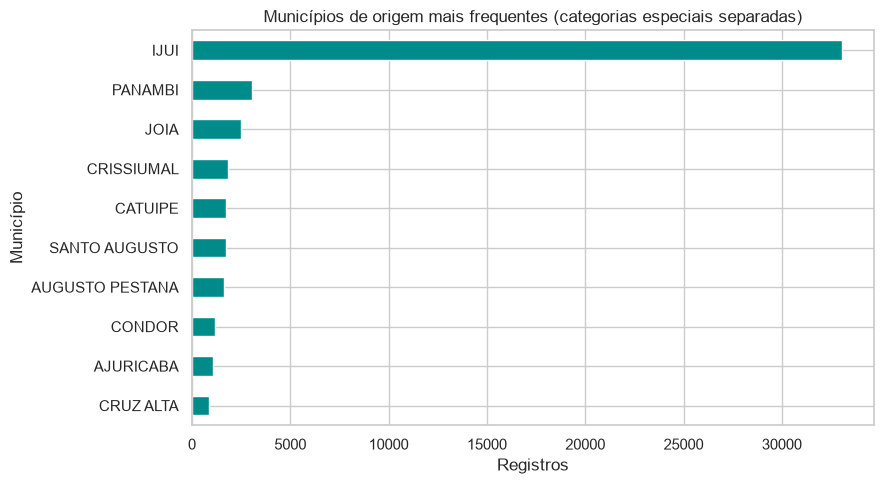

In [42]:
municipios_grafico = frequencia_municipios.head(10).sort_values("Registros")
if not municipios_grafico.empty:
    ax = municipios_grafico["Registros"].plot(kind="barh", figsize=(9, 5), color="darkcyan")
    ax.set_title("Municípios de origem mais frequentes (categorias especiais separadas)")
    ax.set_xlabel("Registros")
    ax.set_ylabel("Município")
    plt.tight_layout()
    plt.savefig(PASTA_IMAGENS / "top10_municipios_origem.png", dpi=160, bbox_inches="tight")
    plt.show()


## 13. Áreas críticas: oncologia, saúde mental e atenção básica

Os recortes abaixo replicam a regra usada pelos scripts do grupo: oncologia por código de procedimento iniciado em `0304`; saúde mental por CID iniciado em `F` ou tipo de unidade `70`; atenção básica por `PA_TPUPS` em `01` ou `02`. Esses filtros são regras de análise do grupo e precisam ser apresentados junto dos resultados.

Se Atenção Básica resultar zero, verifique a frequência de `PA_TPUPS` antes de concluir que não houve produção.


In [43]:
codigo_proc = tabela["PA_PROC_ID"].fillna("").astype("string").str.strip().str.zfill(10)
codigo_cid = tabela["pa_cidpri"].fillna("").astype("string").str.strip().str.upper()
tipo_unidade = tabela["PA_TPUPS"].fillna("").astype("string").str.strip().str.zfill(2)

mascaras_areas = {
    "Oncologia": codigo_proc.str.startswith("0304", na=False),
    "Saude mental": codigo_cid.str.startswith("F", na=False) | tipo_unidade.eq("70"),
    "Atencao basica": tipo_unidade.isin(["01", "02"]),
}
linhas_areas = []
for nome, mascara in mascaras_areas.items():
    parte = tabela.loc[mascara]
    linhas_areas.append({
        "Area": nome,
        "Registros": len(parte),
        "qtd_apresentada": parte["pa_qtdpro"].sum(),
        "qtd_aprovada": parte["pa_qtdapr"].sum(),
        "valor_apresentado": parte["pa_valpro"].sum(),
        "valor_aprovado": parte["pa_valapr"].sum(),
    })
resumo_areas = pd.DataFrame(linhas_areas).set_index("Area")
display(resumo_areas)
salvar_csv(resumo_areas, "resumo_areas_criticas.csv", index=True, index_label="Area")
print("\nFrequência de PA_TPUPS para validar o recorte de Atenção Básica:")
display(tipo_unidade.value_counts(dropna=False).rename_axis("PA_TPUPS").to_frame("Registros"))


,Registros,qtd_apresentada,qtd_aprovada,valor_apresentado,valor_aprovado
Area,,,,,
Oncologia,2253,2132.0,2130.0,2003656.67,1999835.32
Saude mental,12852,50891.0,46568.0,81830.87,71864.99
Atencao basica,0,0.0,0.0,0.00,0.00


CSV salvo: /Users/henrikt/Projects/siasus-base-ciencia-de-dados/analises_geradas/csv/resumo_areas_criticas.csv

Frequência de PA_TPUPS para validar o recorte de Atenção Básica:


,Registros
PA_TPUPS,
05,38655
36,8431
70,8196
68,7573
39,2378
73,203
42,85


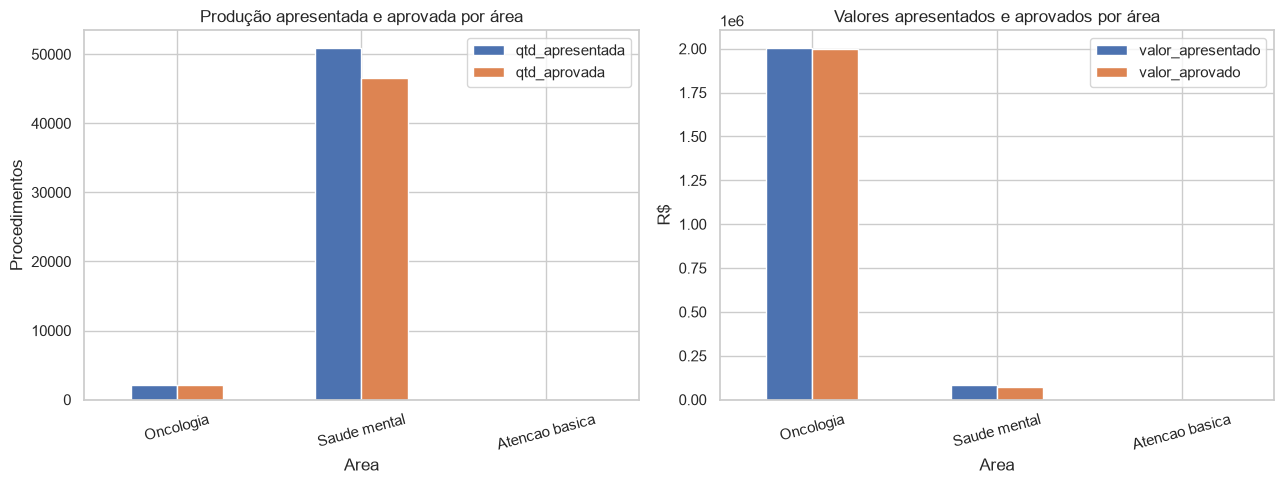

In [44]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
resumo_areas[["qtd_apresentada", "qtd_aprovada"]].plot(kind="bar", ax=eixos[0])
eixos[0].set_title("Produção apresentada e aprovada por área")
eixos[0].set_ylabel("Procedimentos")
eixos[0].tick_params(axis="x", rotation=15)
resumo_areas[["valor_apresentado", "valor_aprovado"]].plot(kind="bar", ax=eixos[1])
eixos[1].set_title("Valores apresentados e aprovados por área")
eixos[1].set_ylabel("R$")
eixos[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "areas_criticas.png", dpi=160, bbox_inches="tight")
plt.show()


## 14. Leitura dos resultados e limitações

Interprete os resultados gerados no MySQL. Na conclusão, identifique os procedimentos e ocupações com maior produção aprovada, os diagnósticos clínicos mais frequentes, as diferenças entre quantidades e valores apresentados e aprovados, os municípios de origem e as áreas críticas em destaque.

Limitações conhecidas do recorte atual:

- Há dados de apenas um mês (2026-07); não é possível concluir tendências nem avaliar a evolução do gasto médio.
- `INVALIDO` e `ESTRANGEIRO` são categorias da tabela auxiliar, não municípios, e não entram na contagem de moradores de outros municípios.
- A view não identifica pessoas únicas; métricas são por registro/quantidade produzida, conforme cada tabela.
- Códigos de sexo fora do esperado, idades inválidas, CID ausente e resultados zerados devem ser relatados como limitações dos dados; os registros não são removidos automaticamente.

### Conclusão do grupo

> Preencha após revisar os resultados e discutir com os integrantes: principais achados, possíveis problemas da informação e recomendações para a gestão municipal.
